Importing Libraries

In [1]:
from scipy.optimize import linprog #import linprog
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt #import libraries for plotting

In [2]:
# read xlsx file

xls = pd.ExcelFile('DC_OPF_data_14.xlsx')
xls.sheet_names

sheet = {}

for sheet_name in xls.sheet_names:
    sheet[sheet_name] = xls.parse(sheet_name)

n_bus = len(sheet['bus'])
k = 24 #number of timestep

Single Line Diagram

Credit to DigSILENT PowerFactory - 14 Bus System


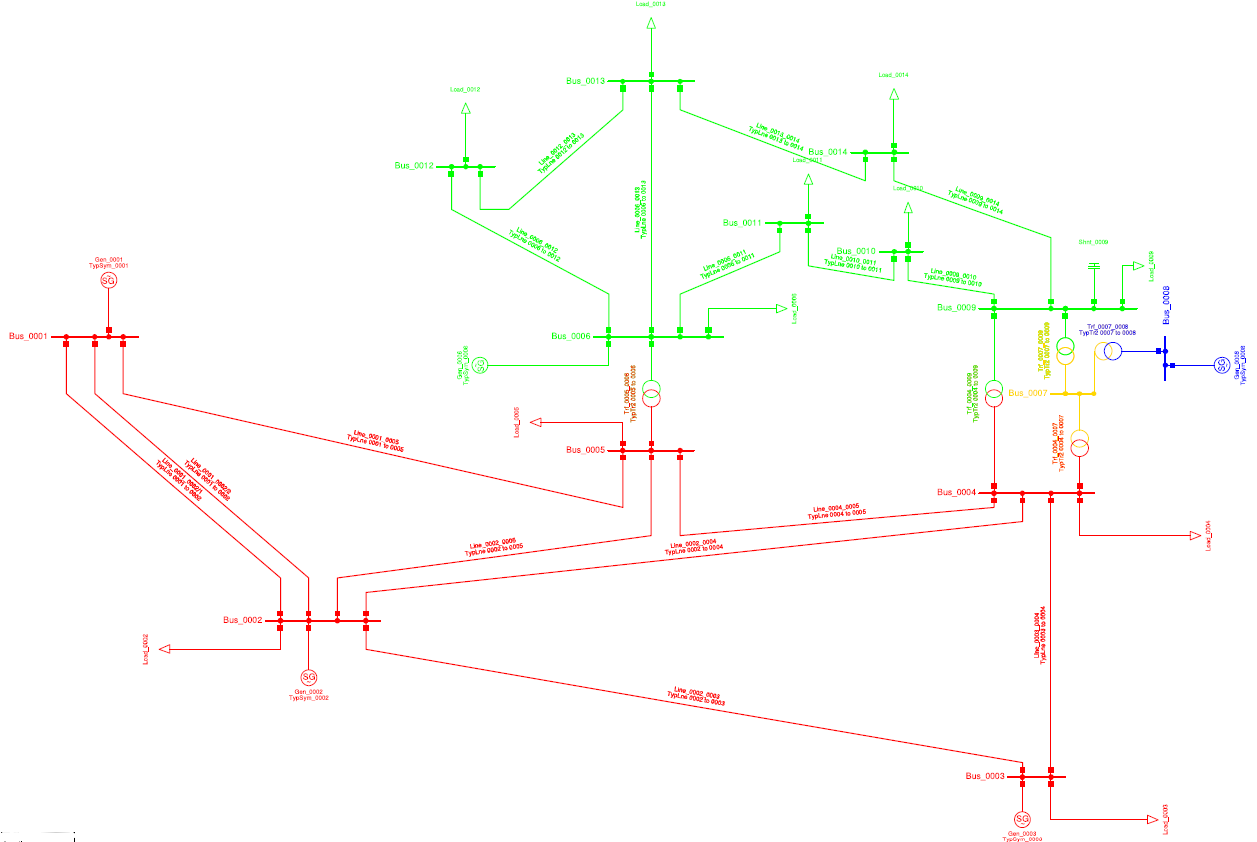

In [3]:
from IPython.display import Image #display image
print("Credit to DigSILENT PowerFactory - 14 Bus System")
Image(filename='IEEE14bus_SLD_v2.png')

In [4]:
print("Lines Parameters")
sheet['lines']

Lines Parameters


,from_bus,to_bus,x_pu,P_max_pu,x_ohm_per_km,Sbase,kVbase,Zbase,Unnamed: 8,Ibase,Ib,Ib_pu
0,1,2,0.059171,4.572614,20.620,100,132,174.24,1.2,0.437387,2,4.572614
1,1,5,0.223037,2.286307,38.862,100,132,174.24,0.5,0.437387,1,2.286307
2,2,3,0.197968,2.286307,34.494,100,132,174.24,0.7,0.437387,1,2.286307
3,2,4,0.176320,2.286307,30.722,100,132,174.24,0.8,0.437387,1,2.286307
4,2,5,0.173881,2.286307,30.297,100,132,174.24,0.4,0.437387,1,2.286307
5,3,4,0.171028,2.286307,29.800,100,132,174.24,0.3,0.437387,1,2.286307
6,4,5,0.042109,2.286307,7.337,100,132,174.24,0.2,0.437387,1,2.286307
7,6,11,0.198898,0.571577,2.166,100,33,10.89,0.3,1.749546,1,0.571577
8,6,12,0.255831,0.571577,2.786,100,33,10.89,0.2,1.749546,1,0.571577
9,6,13,0.130303,0.571577,1.419,100,33,10.89,0.2,1.749546,1,0.571577


In [5]:
print("Transformers Parameters")
sheet['trafos']

Transformers Parameters


,from_bus,to_bus,x_pu,P_max_pu,Unnamed: 4,shift_degree
0,4,7,0.20912,1,0.4,0
1,4,9,0.55618,1,0.2,0
2,5,6,0.25202,1,0.5,0
3,7,8,0.17615,1,0.2,0
4,7,9,0.11001,1,0.2,0


In [6]:
print("Generation and Load Data")
sheet['bus']

Generation and Load Data


,bus,Pg,Pd
0,1,0.0,0.000
1,2,0.4,0.217
2,3,0.0,0.942
3,4,0.0,0.478
4,5,0.0,0.076
5,6,0.0,0.112
6,7,0.0,0.000
7,8,0.0,0.000
8,9,0.0,0.295
9,10,0.0,0.090


In [7]:
#load profile
scale = np.array([0.45, 0.42, 0.40, 0.38, 0.40, 0.45,
                     0.55, 0.70, 0.80, 0.82, 0.80, 0.78,
                     0.75, 0.72, 0.70, 0.72, 0.78, 0.90,
                     1.00, 0.95, 0.88, 0.78, 0.65, 0.52])

base_MVA = 100

#max_gen = sheet['gens']['max_p_mw_pu'][0]

Inequality Constraints

In [8]:
def inequality_constraints():
    H_ineq = []
    K_ineq = []
    
    #-----------------------------------------------------------------------
    
    #inequality constraints of lines loading:
    # abs(\theta_{i}(k) - \theta_{j}(k)) / x_ij <= P_{max,i} (k)
    
    #-----------------------------------------------------------------------
    for i in range(len(sheet['lines'])):
        fr_i = sheet['lines']['from_bus'][i] #from_bus i
        to_j = sheet['lines']['to_bus'][i] #to_bus j
        x_ij = sheet['lines']['x_pu'][i] #line impedances
        Pmax_ij = sheet['lines']['P_max_pu'][i] #rated power
        
        #construct H_part * z <= K_part
        H_part = np.zeros((2*k,(n_bus+2)*k)) #initialize sparse matrix for H_part
        K_part = np.zeros((2*k,1)) #initialize sparse matrix for K_part
        for j in range(k):
            #forward direction of power
            H_part[j,(fr_i-1)*k+j] = 1/x_ij
            H_part[j,(to_j-1)*k+j] = -1/x_ij
            K_part[j] = Pmax_ij
        
            #reverse direction of power
            H_part[k+j,(fr_i-1)*k+j] = -1/x_ij
            H_part[k+j,(to_j-1)*k+j] = 1/x_ij
            K_part[k+j] = Pmax_ij
    
        if i == 0:
            H_ineq = H_part
            K_ineq = K_part
        else:
            H_ineq = np.vstack((H_ineq, H_part))
            K_ineq = np.vstack((K_ineq, K_part))
    
    #-----------------------------------------------------------------------
    
    #inequality constraints for transformers loading:
    # ( \theta_{i}(k) - \theta_{j}(k) ) / x_ij <= P_{max,i} (k) - phi_{ij} - forward direction
    # ( - \theta_{i}(k) + \theta_{j}(k) ) / x_ij <= P_{max,i} (k) + phi_{ij} - reverse direction
    
    #-----------------------------------------------------------------------
    for i in range(len(sheet['trafos'])):
        fr_i = sheet['trafos']['from_bus'][i] #from_bus i
        to_j = sheet['trafos']['to_bus'][i] #to_bus j
        x_ij = sheet['trafos']['x_pu'][i] #trafo impedance
        phi_ij = np.deg2rad(sheet['trafos']['shift_degree'][i]) #phase shift in radian
        Pmax_i = sheet['trafos']['P_max_pu'][i] #rated power of transformer
    
        #construct H_part * z <= K_part
        H_part = np.zeros((2*k,(n_bus+2)*k)) #initialize sparse matrix for H_part
        K_part = np.zeros((2*k,1)) #initialize sparse matrix for K_part
    
        for j in range(k):
            #forward direction
            H_part[j,(fr_i-1)*k+j] = 1/x_ij
            H_part[j,(to_j-1)*k+j] = -1/x_ij
            K_part[j] = Pmax_i - phi_ij/x_ij
    
            #reverse direction
            H_part[k+j,(fr_i-1)*k+j] = -1/x_ij
            H_part[k+j,(to_j-1)*k+j] = 1/x_ij
            K_part[k+j] = Pmax_i + phi_ij/x_ij
        
        #add new sparse inequalities of transformers to existing H_ineq
        H_ineq = np.vstack((H_ineq, H_part))
        K_ineq = np.vstack((K_ineq, K_part))
    
    
    #-----------------------------------------------------------------------
    
    #inequality constraints for generator's loading:
    #P_{grid,min} <= P_{grid}(k) <= P_{grid,max}
    
    #-----------------------------------------------------------------------
    
    #construct H_part * z <= K_part
    H_part = np.zeros((2*k,(n_bus+2)*k)) #initialize sparse matrix for H_part
    K_part = np.zeros((2*k,1)) #initialize sparse matrix for K_part
    
    #fill H_part and K_part elements
    for j in range(k):
        #upper limit of generation
        H_part[j,n_bus*k+j] = 1
        K_part[j] = sheet['gens']['max_p_mw_pu'][0]
    
        #lower limit of generation
        H_part[k+j,n_bus*k+j] = -1
        K_part[k+j] = -sheet['gens']['min_p_mw_pu'][0]
    
    H_ineq = np.vstack((H_ineq, H_part))
    K_ineq = np.vstack((K_ineq, K_part))

    #-----------------------------------------------------------------------
    
    #inequality constraints for PV capacity:
    # 0 <= P_{g,new}(k) <= P_{grid,max}
    
    #-----------------------------------------------------------------------
    H_part = np.zeros((2*k,(n_bus+2)*k)) #initialize H_part
    K_part = np.zeros((2*k,1))
    
    #fill H_part and K_part elements
    for j in range(k):
        #upper limit of generation
        H_part[j,(n_bus+1)*k+j] = 1
        K_part[j] = sheet['gens']['max_p_mw_pu'][0]

        #lower limit of generation
        H_part[k+j,(n_bus+1)*k+j] = -1
    
    H_ineq = np.vstack((H_ineq, H_part))
    K_ineq = np.vstack((K_ineq, K_part))

    #-----------------------------------------------------------------------
    
    #inequality constraints for bus voltage angle:
    # -pi <= \theta_i(k) <= pi
    
    #-----------------------------------------------------------------------
    for i in range(n_bus):
        H_part = np.zeros((2*k,(n_bus+2)*k)) #initialize H_part
        K_part = np.zeros((2*k,1)) #initialize K_part

        for t in range(k):
            # \theta_i(k) <= pi
            H_part[t,i*k+t] = 1
            K_part[t] = math.pi

            # -\theta_i(k) <= pi
            H_part[t+k,i*k+t] = -1
            K_part[t+k] = math.pi

        H_ineq = np.vstack((H_ineq, H_part))
        K_ineq = np.vstack((K_ineq, K_part))
    
    return (H_ineq, K_ineq)

In [9]:
H_ineq, K_ineq = inequality_constraints()
print(H_ineq.shape)
print(K_ineq.shape)

(1728, 384)
(1728, 1)


In [10]:
# JUST FOR CHECKING THE MATRICES

# Define the path to the Excel file
#excel_file_path = 'dataH_ineq.xlsx'

# Convert the NumPy array to a Pandas DataFrame
#df = pd.DataFrame(H_ineq)

# Write the DataFrame to an Excel file
#df.to_excel(excel_file_path, index=False)

In [11]:
# JUST FOR CHECKING THE MATRICES

# Define the path to the Excel file
#excel_file_path = 'dataK_ineq.xlsx'

# Convert the NumPy array to a Pandas DataFrame
#df = pd.DataFrame(K_ineq)

# Write the DataFrame to an Excel file
#df.to_excel(excel_file_path, index=False)

In [12]:
# # Define the single Excel file path
# excel_file_path = 'inequalities_gen.xlsx'

# # Use ExcelWriter to handle multiple sheets
# with pd.ExcelWriter(excel_file_path) as writer:
#     # Convert and write H_ineq
#     df_H = pd.DataFrame(H_ineq)
#     df_H.to_excel(writer, sheet_name='H_ineq', index=False)
    
#     # Convert and write K_ineq
#     df_K = pd.DataFrame(K_ineq)
#     df_K.to_excel(writer, sheet_name='K_ineq', index=False)

Equality Constraints

In [13]:
def equality_constraints(new_gen_bus):
    H_eq = []
    K_eq = []
    
    #-----------------------------------------------------------------------
    
    #equality constraints for slack bus
    # \theta_1 (k) = 0
    
    #-----------------------------------------------------------------------
    H_part = np.zeros((k, (n_bus+2)*k)) #initialize sparse matrix for H_part
    K_part = np.zeros((k,1)) #initialize sparse matrix for K_part
    slack = sheet['gens']['bus'][0]
    for t in range(k):
        H_part[t,(slack-1)*k+t] = 1
    
    H_eq = H_part
    K_eq = K_part
    
    #equality constraints for branch power flows
    for i in range(len(sheet['bus'])):
        H_part = np.zeros((k, (n_bus+2)*k)) #initialize sparse matrix for H_part
        K_part = np.zeros((k,1)) #initialize sparse matrix for K_part
        H_temp = 0
    
        #fill K_part elements
        for t in range(k):
            K_part[t,0] = sheet['bus']['Pg'][i]*scale[t] - sheet['bus']['Pd'][i]*scale[t]
    
        #search common branch in lines sheet
        for j in range(len(sheet['lines'])):
            x_ij = sheet['lines']['x_pu'][j]
            if (sheet['lines']['from_bus'][j]-1) == i:
                to_j = sheet['lines']['to_bus'][j]
                H_temp = H_temp + 1 / x_ij
                for t in range(k):
                    H_part[t,(to_j-1)*k+t] = -1/x_ij
            if (sheet['lines']['to_bus'][j]-1) == i:
                fr_i = sheet['lines']['from_bus'][j]
                H_temp = H_temp + 1 / x_ij
                for t in range(k):
                    H_part[t,(fr_i-1)*k+t] = -1/x_ij
    
        #search common branch in trafos sheet
        for j in range(len(sheet['trafos'])):
            x_ij = sheet['trafos']['x_pu'][j]
            phi_ij = np.deg2rad(sheet['trafos']['shift_degree'][j])
            to_j = sheet['trafos']['to_bus'][j]
            fr_i = sheet['trafos']['from_bus'][j]
            
            if (fr_i-1) == i:    
                H_temp = H_temp + 1 / x_ij
                for t in range(k):
                    H_part[t,(to_j-1)*k+t] = -1 / x_ij
                    K_part[t,0] = K_part[t,0] - phi_ij / x_ij
            if (to_j-1) == i:
                H_temp = H_temp + 1 / x_ij
                for t in range(k):
                    H_part[t,(fr_i-1)*k+t] = -1 / x_ij
                    K_part[t,0] = K_part[t,0] + phi_ij / x_ij
        for t in range(k):
            H_part[t,i*k+t] = H_temp
    
        #search external grid in the same bus
        if (sheet['gens']['bus'][0]-1) == i:
            for t in range(k):
                H_part[t,(n_bus)*k+t] = -1
        
        #search New generation in the same bus
        if (new_gen_bus) == i:
            for t in range(k):
                H_part[t,(n_bus+1)*k+t] = -1
    
        H_eq = np.vstack((H_eq, H_part))
        K_eq = np.vstack((K_eq, K_part))
    
    return(H_eq, K_eq)

In [14]:
#printing equality constraints for specific bus injection
H_eq, K_eq = equality_constraints(5)
print(H_eq.shape)
print(K_eq.shape)

(360, 384)
(360, 1)


In [15]:
# JUST FOR CHECKING WHETHER THE MATRIX IS CORRECT

# Define the path to the Excel file
#excel_file_path = 'dataH_eq.xlsx'

# Convert the NumPy array to a Pandas DataFrame
#df = pd.DataFrame(H_eq)

# Write the DataFrame to an Excel file
#df.to_excel(excel_file_path, index=False)

In [16]:
# JUST FOR CHECKING WHETHER THE MATRIX IS CORRECT

# Define the path to the Excel file
#excel_file_path = 'dataK_eq.xlsx'

# Convert the NumPy array to a Pandas DataFrame
#df = pd.DataFrame(K_eq)

# Write the DataFrame to an Excel file
#df.to_excel(excel_file_path, index=False)

In [17]:
# # Define the single Excel file path
# excel_file_path = 'equalities_gen.xlsx'

# # Use ExcelWriter to handle multiple sheets
# with pd.ExcelWriter(excel_file_path) as writer:
#     # Convert and write H_ineq
#     df_H = pd.DataFrame(H_eq)
#     df_H.to_excel(writer, sheet_name='H_eq', index=False)
    
#     # Convert and write K_ineq
#     df_K = pd.DataFrame(K_eq)
#     df_K.to_excel(writer, sheet_name='K_eq', index=False)

LP Formulation

In [38]:
#defining objective function
c = np.zeros((1,(n_bus+2)*k))
for ts in range(k):
    c[0,(n_bus+1)*k+ts] = -1
#for ts in range(k):
#    c[0,(n_bus)*k+ts] = -1 #maximize S^{PV}

#initializing variables to store optimization results
theta_k = []
Pgrid_k = []
PV_cap = []

#extracting inequality constraints
H_ineq, K_ineq = inequality_constraints()

bounds = [(None, None)] * (n_bus * k) + [(0, None)] * k + [(0, None)] * k

line_ol = 0
trafo_ol = 0
grid_lim = 0
gen_lim = 0

#iterating for solving optimization in each bus
for i in range(n_bus):

    #extracting equality constraints
    H_eq, K_eq = equality_constraints(i)

    #solve LP
    res = linprog(c, A_ub=H_ineq, b_ub=K_ineq, A_eq = H_eq, b_eq=K_eq, bounds=bounds)
    #print("Optimization for new PV at bus " + str(i+1) + ": " + res.message)

    for idx, slack_val in enumerate(res.slack):
        is_active = np.isclose(slack_val, 0, atol=1e-7)
        if is_active:
            if (idx>=0) & (idx<=len(sheet['lines'])*2*k-1):
                #print(f"Line Overloading")
                line_ol += 1
            elif (idx>len(sheet['lines'])*2*k-1) & (idx<=len(sheet['lines'])*2*k+len(sheet['trafos'])*2*k-1):
                #print(f"Trafo Overloading")
                trafo_ol += 1
            elif (idx>len(sheet['lines'])*2*k+len(sheet['trafos'])*2*k-1) & (idx<=len(sheet['lines'])*2*k+len(sheet['trafos'])*2*k+2*k-1):
                #print(f"Grid limit")
                grid_lim += 1
            elif (idx>len(sheet['lines'])*2*k+len(sheet['trafos'])*2*k+2*k-1) & (idx<=len(sheet['lines'])*2*k+len(sheet['trafos'])*2*k+4*k-1):
                #print(f"New generator limit")
                gen_lim += 1
            #print(f"Constraint row {idx} slack: {slack_val} -> Active? {is_active}")

    #storing optimization results
    if i == 0:
        theta_k = res.x[0:(n_bus)*k]*180/math.pi
        Pgrid_k = res.x[(n_bus)*k:(n_bus+1)*k] * base_MVA
        Pgen_k = res.x[(n_bus+1)*k:(n_bus+2)*k] * base_MVA
    else:
        theta_k = np.vstack((theta_k, res.x[0:(n_bus)*k]*180/math.pi))
        Pgrid_k = np.vstack((Pgrid_k, res.x[(n_bus)*k:(n_bus+1)*k] * base_MVA))
        Pgen_k = np.vstack((Pgen_k, res.x[(n_bus+1)*k:(n_bus+2)*k] * base_MVA))

print("Line overload " + str(line_ol) + " instances")
print("Trafo overload " + str(trafo_ol) + " instances")
print("Grid Limit " + str(grid_lim) + " instances")
print("Generator Limit " + str(gen_lim) + " instances")

Line overload 95 instances
Trafo overload 21 instances
Grid Limit 220 instances
Generator Limit 0 instances


In [19]:
#printing bus voltage angle

#for i in range(n_bus):
#    print("Bus voltage angle for PV injection at bus " + str(i+1))
#    for n in range(n_bus):
#        print("Bus " + str(n+1) + " voltage angle")
#        print(theta_k[i][(n)*k:(n+1)*k])
#    print("---------------------------------------------------------------------")

In [20]:
#printing hosting capacity of PV in each bus

for i in range(n_bus):
    print("Max Generation [MW] at Bus " + str(i+1) + " injection = " + str(round(max(Pgen_k[i]),2)) + " MW")
    print("Min Generation [MW] at Bus " + str(i+1) + " injection = " + str(round(min(Pgen_k[i]),2)) + " MW")
    print("-----------------------------------------------------------------------------------------------")

Max Generation [MW] at Bus 1 injection = 219.0 MW
Min Generation [MW] at Bus 1 injection = 83.22 MW
-----------------------------------------------------------------------------------------------
Max Generation [MW] at Bus 2 injection = 219.0 MW
Min Generation [MW] at Bus 2 injection = 83.22 MW
-----------------------------------------------------------------------------------------------
Max Generation [MW] at Bus 3 injection = 219.0 MW
Min Generation [MW] at Bus 3 injection = 83.22 MW
-----------------------------------------------------------------------------------------------
Max Generation [MW] at Bus 4 injection = 219.0 MW
Min Generation [MW] at Bus 4 injection = 83.22 MW
-----------------------------------------------------------------------------------------------
Max Generation [MW] at Bus 5 injection = 219.0 MW
Min Generation [MW] at Bus 5 injection = 83.22 MW
-----------------------------------------------------------------------------------------------
Max Generation [MW] 

Plotting

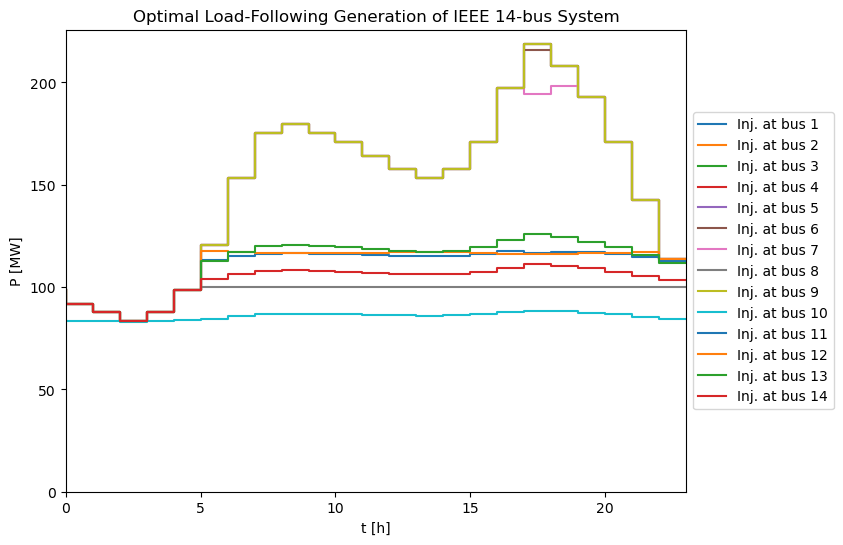

In [21]:
#-----------------------------------------------------------------------
    
#Plotting PV power for each bus injection of PV
    
#-----------------------------------------------------------------------

#initialize for generating set of legends
lgnd = []
t = np.array([0,1,2,3,4,5,
             6,7,8,9,10,11,
             12,13,14,15,16,17,
             18,19,20,21,22,23])

plt.figure(figsize=(8,6))
for bus in range(n_bus):
    #plot step graph
    plt.step(t,Pgen_k[bus])

    #generate and concatenate legends
    if len(lgnd) == 0:
        lgnd = ["Inj. at bus " + str(bus+1)]
    else:
        lgnd = np.hstack((lgnd, ["Inj. at bus " + str(bus+1)]))

#plot settings
plt.xlabel("t [h]")
plt.ylabel("P [MW]")
plt.title("Optimal Load-Following Generation of IEEE 14-bus System")
plt.legend(lgnd,loc='center left', bbox_to_anchor=(1, 0.5))
plt.ylim(bottom=0)
plt.xlim(0,23)
plt.savefig('lfgieee14bus', bbox_inches = 'tight')
plt.show()

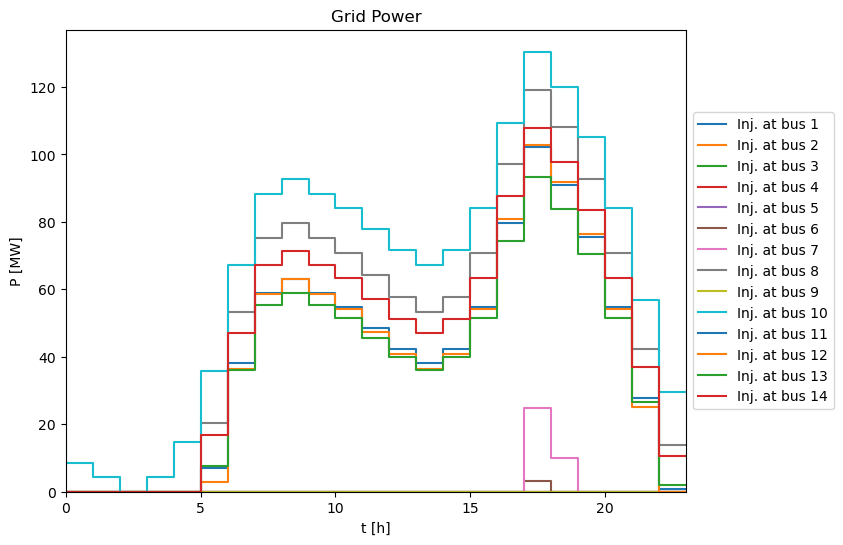

In [22]:
#-----------------------------------------------------------------------
    
#Plotting Grid power for each bus injection of PV
    
#-----------------------------------------------------------------------

#initialize for generating set of legends
lgnd = []
t = np.array([0,1,2,3,4,5,
             6,7,8,9,10,11,
             12,13,14,15,16,17,
             18,19,20,21,22,23])

plt.figure(figsize=(8,6))
for bus in range(n_bus):
    #plot step graph
    plt.step(t,Pgrid_k[bus])

    #generate and concatenate legends
    if len(lgnd) == 0:
        lgnd = ["Inj. at bus " + str(bus+1)]
    else:
        lgnd = np.hstack((lgnd, ["Inj. at bus " + str(bus+1)]))

#plot settings
plt.xlabel("t [h]")
plt.ylabel("P [MW]")
plt.title("Grid Power")
plt.legend(lgnd,loc='center left', bbox_to_anchor=(1, 0.5))
plt.ylim(bottom=0)
plt.xlim(0,23)
plt.savefig('lfgieee14bus_grid', bbox_inches = 'tight')
plt.show()

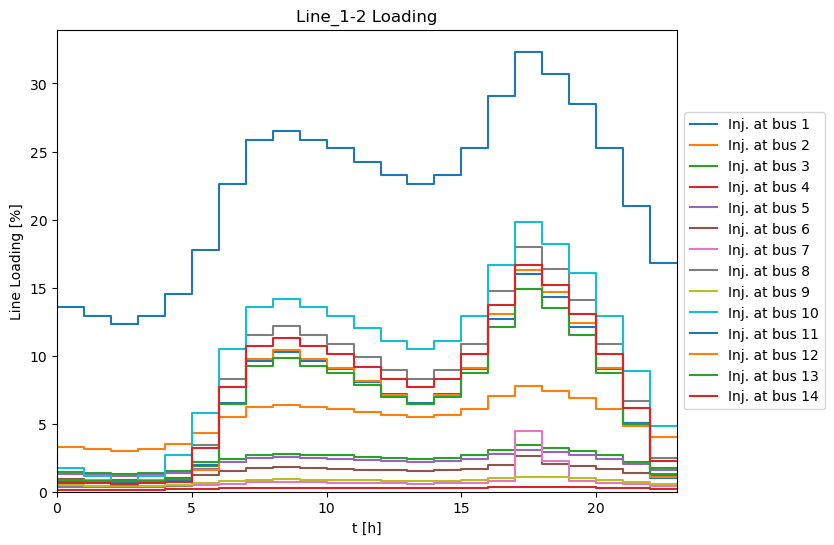

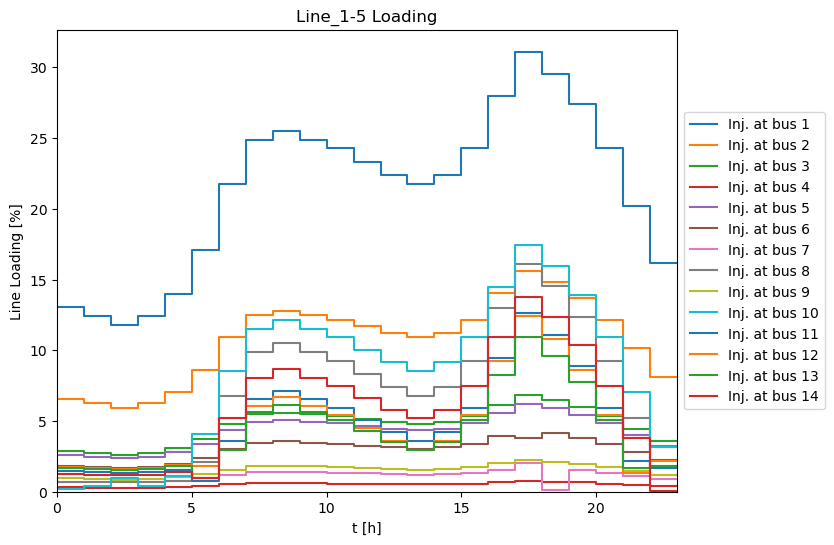

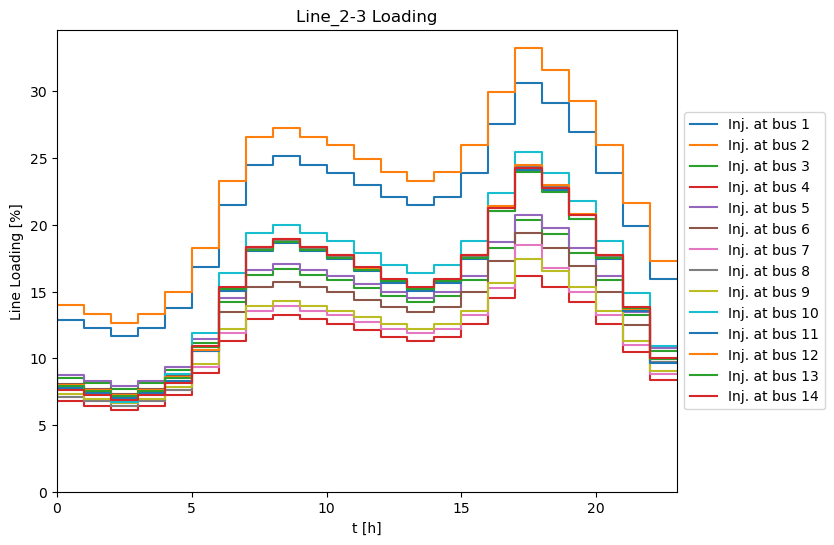

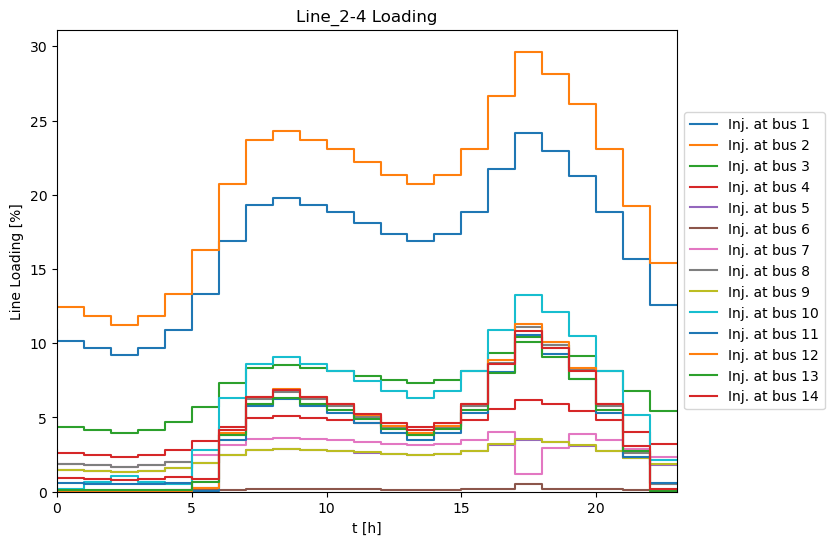

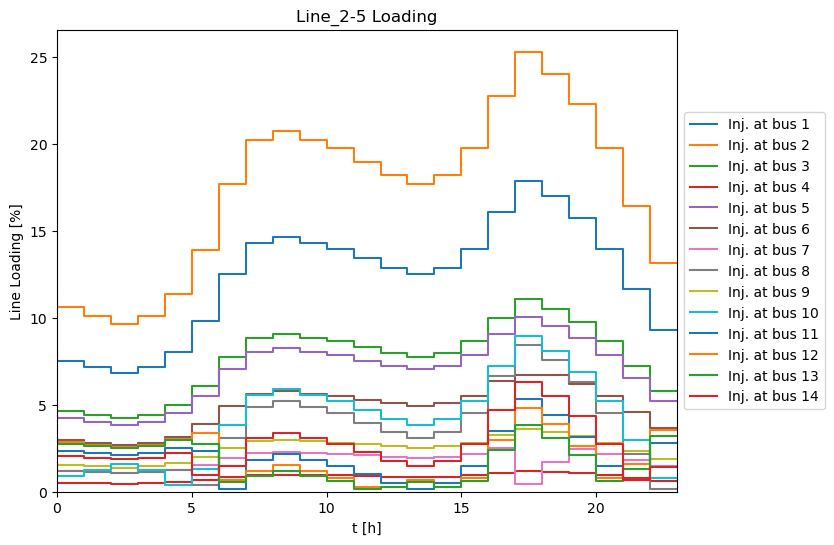

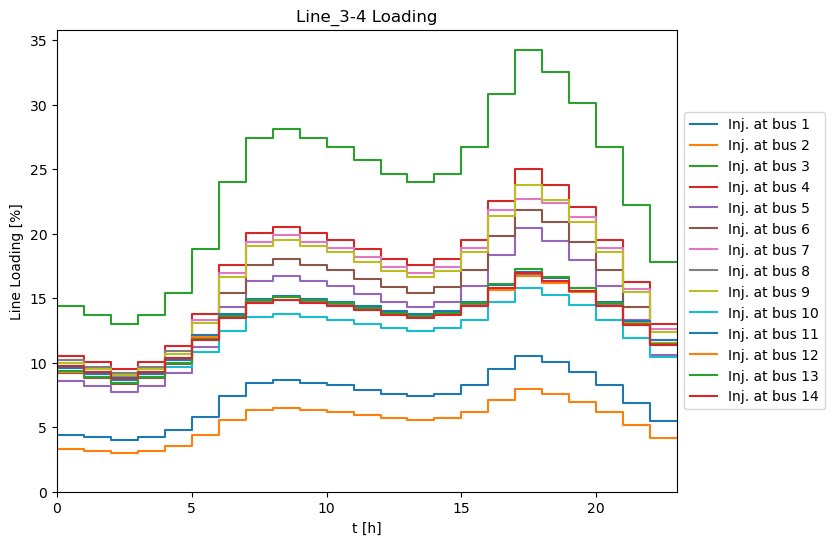

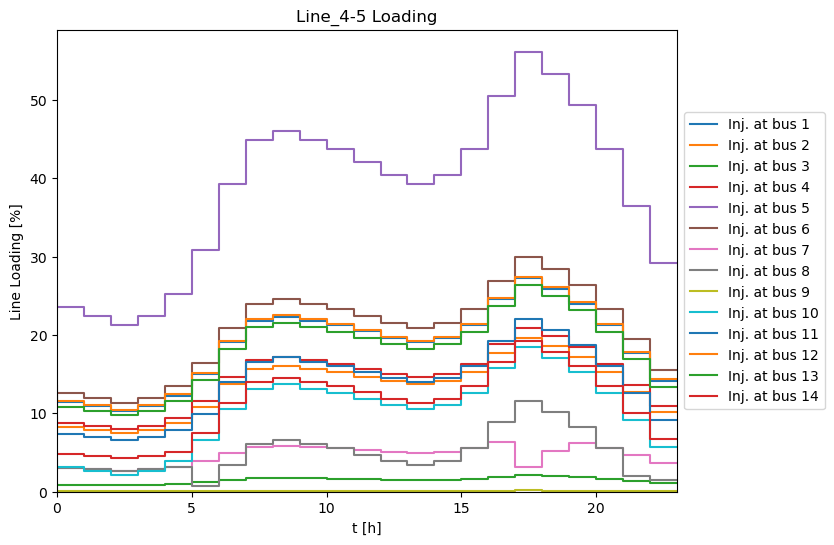

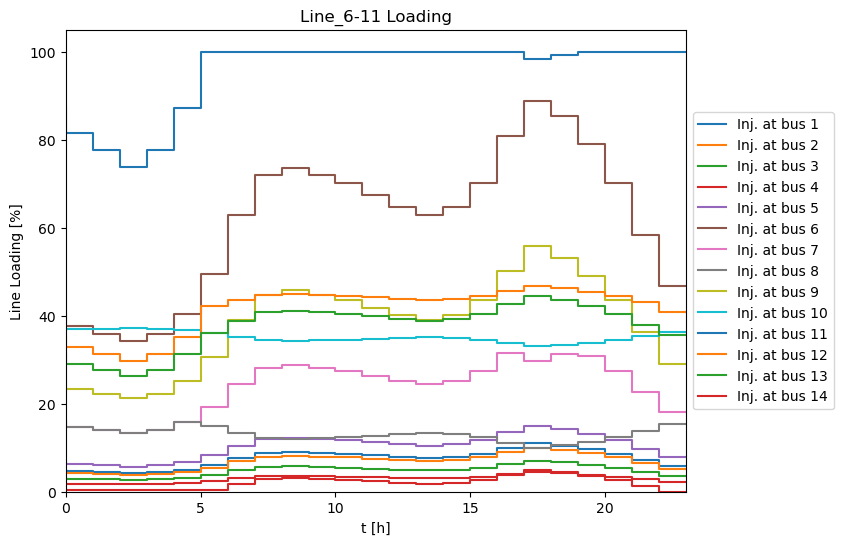

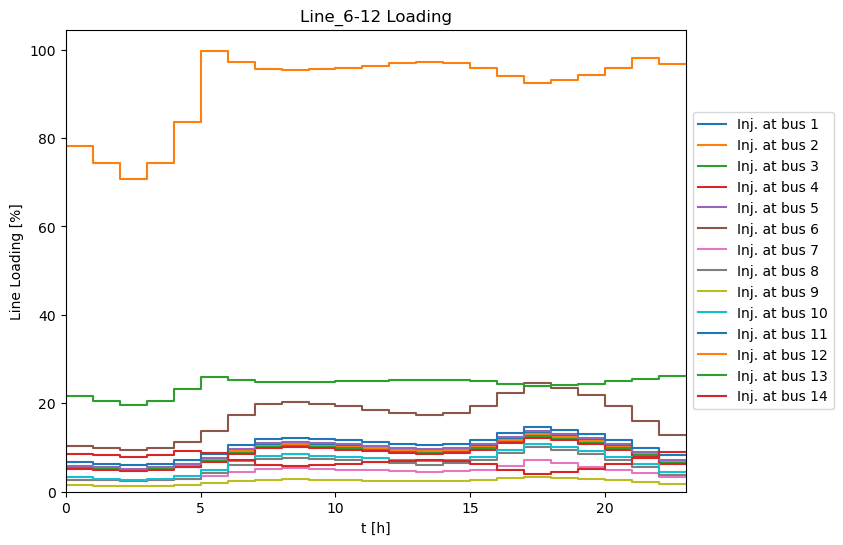

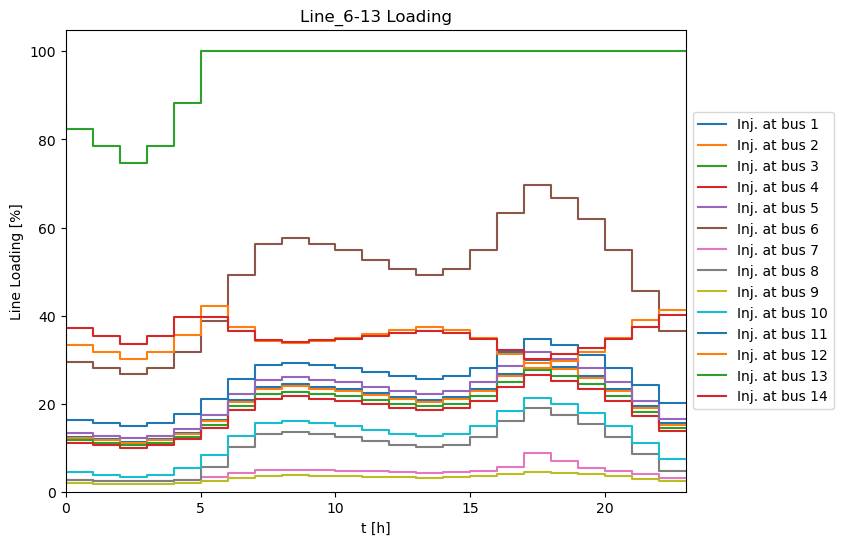

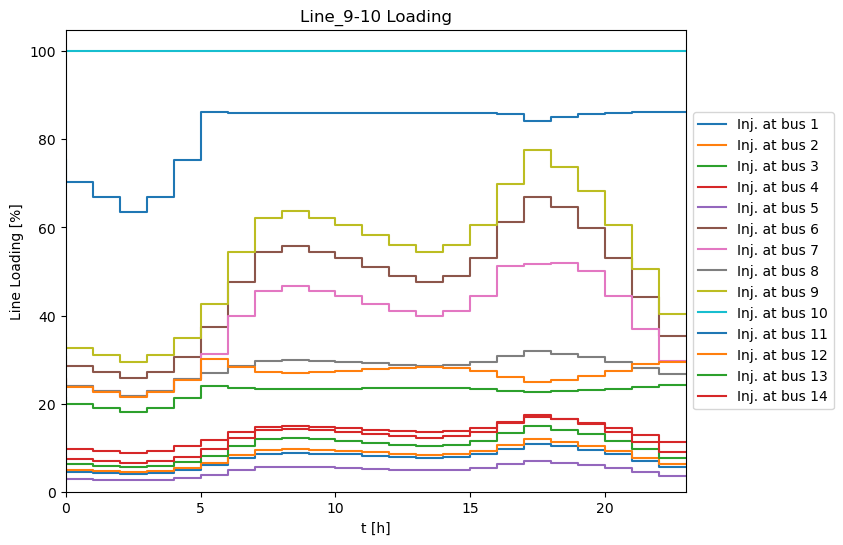

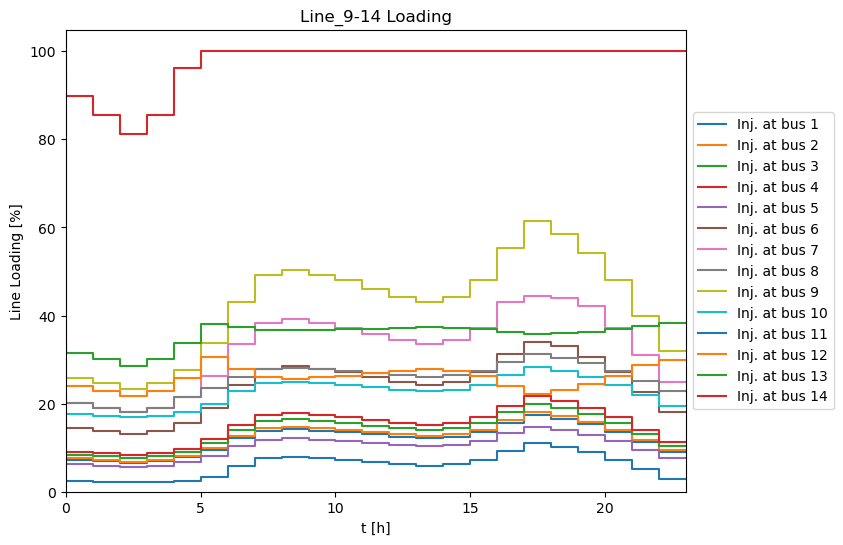

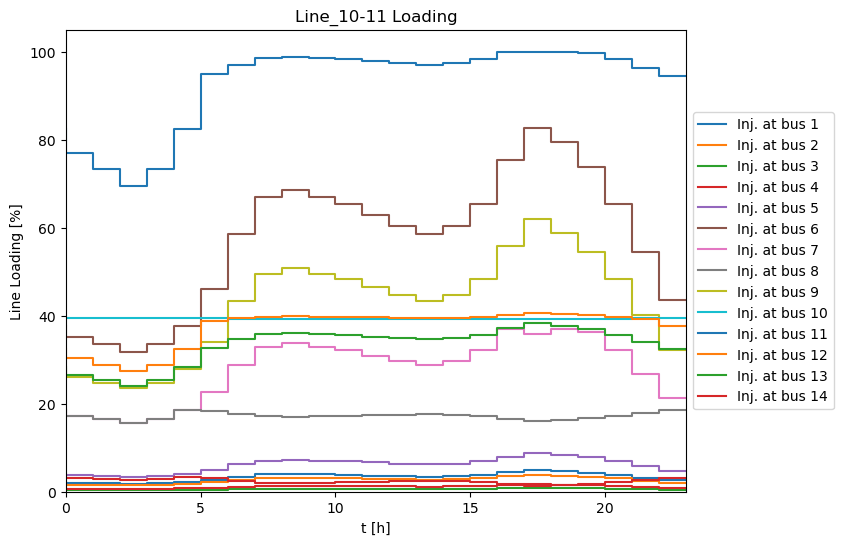

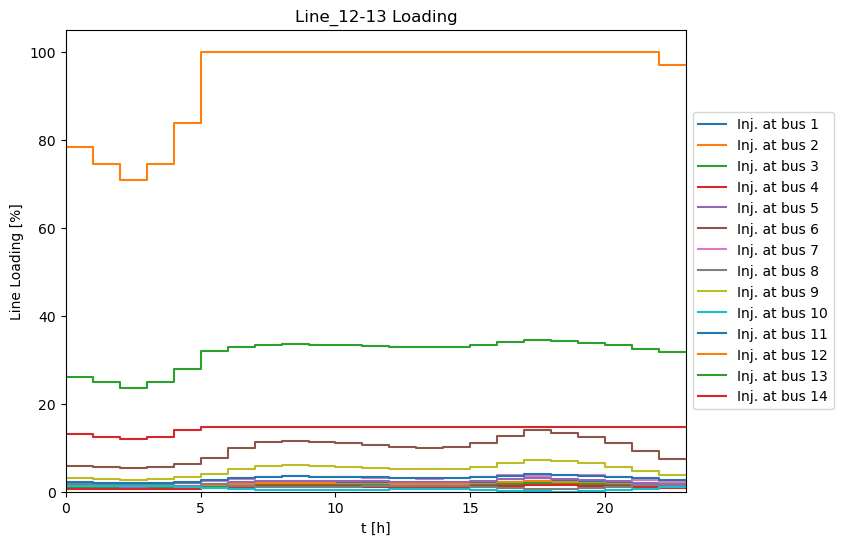

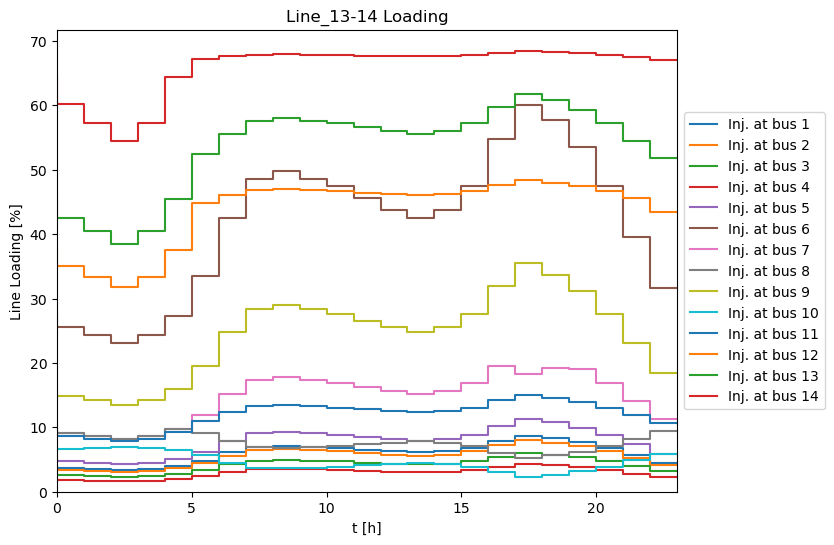

In [23]:
#-----------------------------------------------------------------------
    
#Plotting Line Loading for each bus injection of PV
    
#-----------------------------------------------------------------------

for i in range(len(sheet['lines'])):

    #extracting line parameters
    Pmax_ij = sheet['lines']['P_max_pu'][i]
    x_ij = sheet['lines']['x_pu'][i]
    fr_i = sheet['lines']['from_bus'][i]
    to_j = sheet['lines']['to_bus'][i]
    
    #initialize for generating set of legends
    lgnd = []
    t = np.array([0,1,2,3,4,5,
                 6,7,8,9,10,11,
                 12,13,14,15,16,17,
                 18,19,20,21,22,23])
    
    plt.figure(figsize=(8,6))
    
    for bus in range(n_bus):
        lineLoad = []
        for ts in range(k):
            lineLoad = np.hstack((lineLoad, 100*abs(np.deg2rad(theta_k[bus][(fr_i-1)*k+ts]) - np.deg2rad(theta_k[bus][(to_j-1)*k+ts])) / (x_ij * Pmax_ij)))
            
        if bus != (sheet['gens']['bus'][0]-100):
            #plot step graph
            plt.step(t, lineLoad)
    
            #generate and concatenate legends
            if len(lgnd) == 0:
                lgnd = ["Inj. at bus " + str(bus+1)]
            else:
                lgnd = np.hstack((lgnd, ["Inj. at bus " + str(bus+1)]))
    
    #plot settings
    plt.xlabel("t [h]")
    plt.ylabel("Line Loading [%]")
    plt.title("Line_" + str(min(sheet['lines']['from_bus'][i],sheet['lines']['to_bus'][i])) + "-" + str(max(sheet['lines']['from_bus'][i],sheet['lines']['to_bus'][i])) + " Loading")
    plt.legend(lgnd,loc='center left', bbox_to_anchor=(1, 0.5))
    plt.ylim(bottom=0)
    plt.xlim(0,23)
    plt.show()

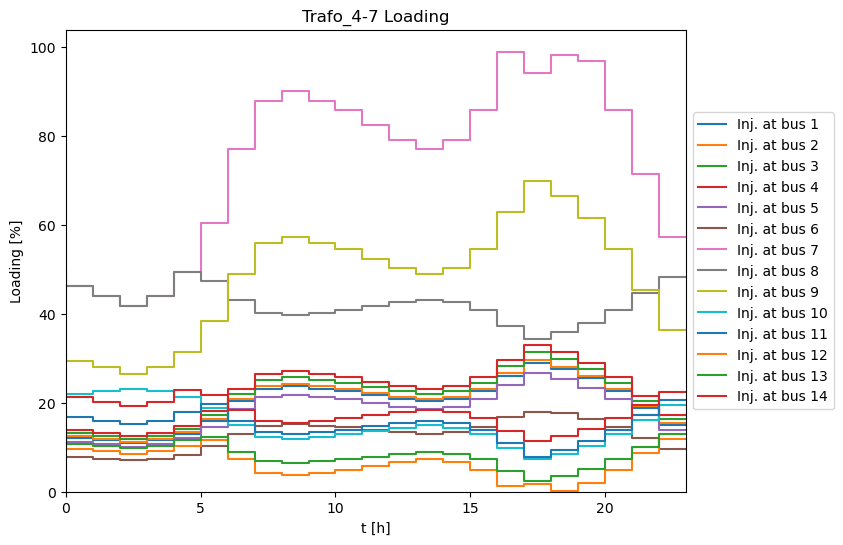

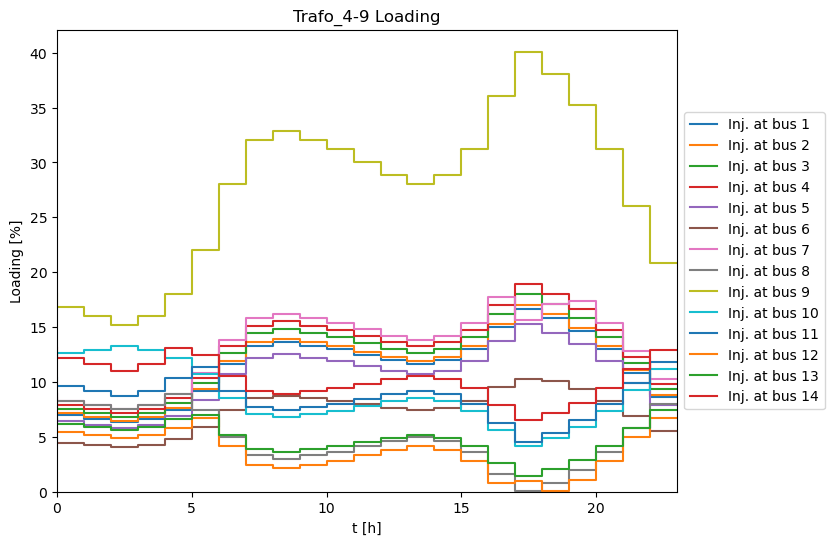

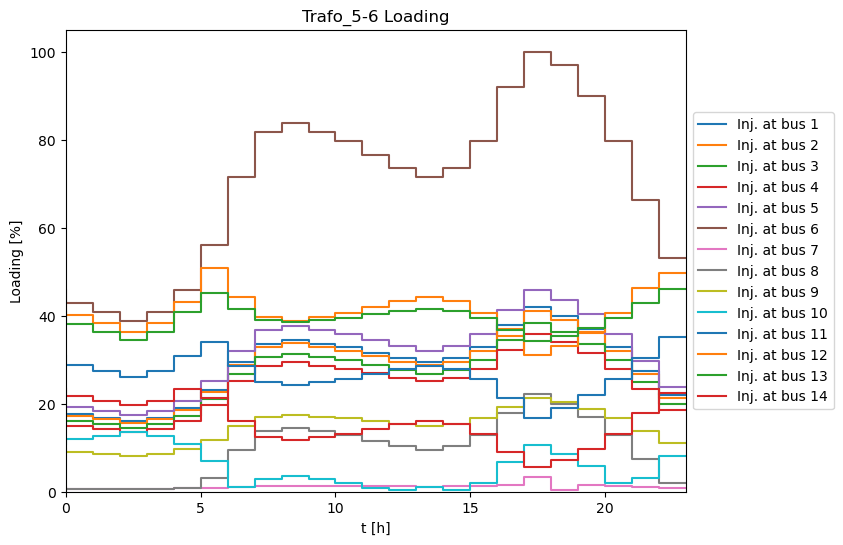

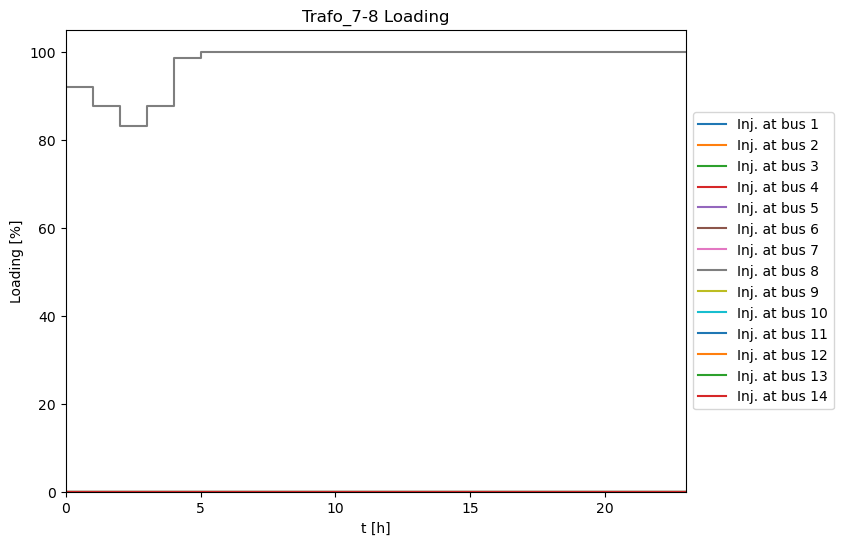

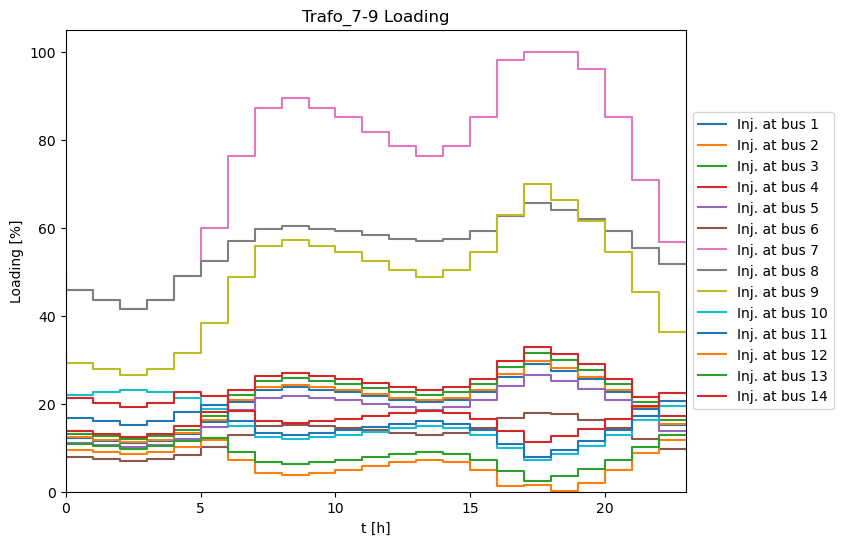

In [24]:
#-----------------------------------------------------------------------
    
#Plotting Transformer Loading for each bus injection of PV
    
#-----------------------------------------------------------------------

for i in range(len(sheet['trafos'])):

    #extracting line parameters
    Pmax_ij = sheet['trafos']['P_max_pu'][i]
    x_ij = sheet['trafos']['x_pu'][i]
    phi_ij = np.deg2rad(sheet['trafos']['shift_degree'][i])
    fr_i = sheet['trafos']['from_bus'][i]
    to_j = sheet['trafos']['to_bus'][i]
    
    #initialize for generating set of legends
    lgnd = []
    t = np.array([0,1,2,3,4,5,
                 6,7,8,9,10,11,
                 12,13,14,15,16,17,
                 18,19,20,21,22,23])
    
    plt.figure(figsize=(8,6))
    
    for bus in range(n_bus):
        trafoLoad = []
        for ts in range(k):
            trafoLoad = np.hstack((trafoLoad, 100*abs(np.deg2rad(theta_k[bus][(fr_i-1)*k+ts]) - np.deg2rad(theta_k[bus][(to_j-1)*k+ts]) + phi_ij) / (x_ij * Pmax_ij)))
            
        if bus != (sheet['gens']['bus'][0]-100):
            #plot step graph
            plt.step(t, trafoLoad)
    
            #generate and concatenate legends
            if len(lgnd) == 0:
                lgnd = ["Inj. at bus " + str(bus+1)]
            else:
                lgnd = np.hstack((lgnd, ["Inj. at bus " + str(bus+1)]))
    
    #plot settings
    plt.xlabel("t [h]")
    plt.ylabel("Loading [%]")
    plt.title("Trafo_" + str(min(sheet['trafos']['from_bus'][i],sheet['trafos']['to_bus'][i])) + "-" + str(max(sheet['trafos']['from_bus'][i],sheet['trafos']['to_bus'][i])) + " Loading")
    plt.legend(lgnd,loc='center left', bbox_to_anchor=(1, 0.5))
    plt.ylim(bottom=0)
    plt.xlim(0,23)
    plt.show()

Comparison with AC Power Flow

In [25]:
import pandapower as pp
from pandapower.timeseries import run_timeseries, OutputWriter
from pandapower.control import ConstControl
from pandapower.timeseries import DFData
from pandapower import from_pickle #loading existing SLD
from pandapower.create import create_gen

In [26]:
def load_network():
    return from_pickle("ieee14bus.p")

In [27]:
def grid_conditions(ac_grid_mw,i):
    # 1. Force the Pandas DataFrame into a flat 1D NumPy array of 24 values
    ac_grid_numpy = ac_grid_mw.values.flatten()
    
    # 2. Get your LP grid array as a flat 1D array of 24 values
    lp_grid_numpy = Pgrid_k[i, :].flatten()
    
    # 3. Calculate the difference in megawatts
    loss_error_mw = ac_grid_numpy - lp_grid_numpy
    
    # 4. Calculate Mean Absolute Error (MAE) instead of MAPE
    slack_mae_mw = np.mean(np.abs(loss_error_mw))
    slack_mae_mw_percent = slack_mae_mw / 259 * 100
    
    # Standard deviation of the absolute error in Megawatts
    slack_std_mw = np.std(np.abs(loss_error_mw))
    slack_std_percent = slack_std_mw / 259 * 100
    
    print(f"Average Slack Bus Deviation due to Losses: {slack_mae_mw:.2f} MW")
    print(f"Percentage deviation =  {round(slack_mae_mw_percent,2)} percent")

    print(f"Standard Deviation of Deviation: {slack_std_mw:.2f} MW")
    print(f"Percentage standard deviation = {round(slack_std_percent, 2)} percent")
    
    #print("Losses per hour (MW):\n", loss_error_mw)


In [28]:
def bus_angle_conditions(ac_bus_angles,i):
    # 1. Convert the pandapower AC DataFrame results into a raw 24x9 NumPy matrix
    ac_angles_np = ac_bus_angles.values  # Shape is (24, 9)
    
    # 2. Reshape theta_k based on how your LP exported it (9 buses, 24 hours)
    # This results in a shape of (14, 24)
    lp_angles_reshaped = theta_k[i].reshape(14, 24)
    
    # 3. Transpose the matrix (.T) so it becomes (24, 9) to match pandapower exactly
    lp_angles_degrees = lp_angles_reshaped.T  # Now shape is (24, 9)
    
    # 4. Calculate the Mean Absolute Error (MAE) safely
    angle_mae = np.mean(np.abs(ac_angles_np - lp_angles_degrees))
    
    print(f"Mean Absolute Error for Voltage Angles: {angle_mae:.4f} degrees")


In [29]:
def bus_voltage_conditions(ac_bus_voltage):
    # 1. Convert the pandapower AC DataFrame results into a raw 24x9 NumPy matrix
    ac_bus_voltage_np = ac_bus_voltage.values  # Shape is (24, 9)
    
    # 2. Calculate the Mean Absolute Error (MAE) safely
    magnitude_mae = np.mean(np.abs(ac_bus_voltage_np - 1))
    
    print(f"Mean Absolute Error for Voltage Magnitude: {magnitude_mae:.4f} p.u.")

In [30]:
def line_conditions(ac_line_loading):
    # 1. Convert the pandapower line loading DataFrame to a raw numpy array if it isn't already
    # ac_line_loading_np shape: (24 timesteps, number_of_lines)
    ac_line_loading_np = ac_line_loading.values if hasattr(ac_line_loading, "values") else ac_line_loading
    
    # 2. Find coordinates where loading exceeds 100%
    # timesteps contains the row numbers (hours), lines contains the column numbers (line IDs)
    timesteps, lines = np.where(ac_line_loading_np > 105)
    
    # 3. Print the results
    if len(lines) > 0:
        print(f"Detected {len(lines)} instances of physical line overloading under AC conditions:\n")
        print(f"{'Hour':<8} | {'Line ID':<10} | {'AC Loading %'}")
        print("-" * 35)
        
        for t, line_id in zip(timesteps, lines):
            loading_value = ac_line_loading_np[t, line_id]
            print(f"{t:<8} | {line_id:<10} | {loading_value:.2f}%")
    else:
        print("Excellent! No lines were physically overloaded during any timestep.")


In [31]:
def trafo_conditions(ac_trafo_loading):
    # 1. Convert the pandapower line loading DataFrame to a raw numpy array if it isn't already
    # ac_line_loading_np shape: (24 timesteps, number_of_lines)
    ac_trafo_loading_np = ac_trafo_loading.values if hasattr(ac_trafo_loading, "values") else ac_trafo_loading
    
    # 2. Find coordinates where loading exceeds 100%
    # timesteps contains the row numbers (hours), lines contains the column numbers (line IDs)
    timesteps, trafos = np.where(ac_trafo_loading_np > 105)
    
    # 3. Print the results
    if len(trafos) > 0:
        print(f"Detected {len(trafos)} instances of physical trafo overloading under AC conditions:\n")
        print(f"{'Hour':<8} | {'Trafo ID':<10} | {'AC Loading %'}")
        print("-" * 35)
        
        for t, trafo_id in zip(timesteps, trafos):
            loading_value = ac_trafo_loading_np[t, trafo_id]
            print(f"{t:<8} | {trafo_id:<10} | {loading_value:.2f}%")
    else:
        print("Excellent! No trafos were physically overloaded during any timestep.")


In [32]:
def choose_bus(net,i):
    return net.load.bus.values[i]

In [33]:
bus_angle = []
bus_voltage = []
for i in range(n_bus):
    if i != (sheet['gens']['bus'][0]-1):
        net = load_network()
        
        #read timeseries data from csv files
        df_gen_mw = pd.read_csv("gen_p_mw_ts.csv", sep=';', index_col=0)
        df_gen_mvar = pd.read_csv("gen_q_mvar_ts.csv", sep=';', index_col=0)
        df_load_mw = pd.read_csv("load_p_mw_ts.csv", sep=';', index_col=0)
        df_load_mvar = pd.read_csv("load_q_mvar_ts.csv", sep=';', index_col=0)
        
        #convert columns to integers
        df_gen_mw.columns = df_gen_mw.columns.astype(int)
        df_gen_mvar.columns = df_gen_mvar.columns.astype(int)
        df_load_mw.columns = df_load_mw.columns.astype(int)
        df_load_mvar.columns = df_load_mvar.columns.astype(int)
        
        #convert timeseries data to dataframe
        ds_gen_mw = DFData(df_gen_mw)
        ds_gen_mvar = DFData(df_gen_mvar)
        ds_load_mw = DFData(df_load_mw)
        ds_load_mvar = DFData(df_load_mvar)
        
        #convert dataframe columns into list of integers
        ds_gen_mw_indices = df_gen_mw.columns.tolist()
        ds_gen_mvar_indices = df_gen_mvar.columns.tolist()
        ds_load_mw_indices = df_load_mw.columns.tolist()
        ds_load_mvar_indices = df_load_mvar.columns.tolist()
        
        #link dataframe to generator and load
        ConstControl(net, element='gen', variable='p_mw', element_index=ds_gen_mw_indices, data_source=ds_gen_mw, profile_name=ds_gen_mw_indices)
        #ConstControl(net, element='gen', variable='q_mvar', element_index=ds_gen_mvar_indices, data_source=ds_gen_mvar, profile_name=ds_gen_mvar_indices)
        ConstControl(net, element='load', variable='p_mw', element_index=ds_load_mw_indices, data_source=ds_load_mw, profile_name=ds_load_mw_indices)
        ConstControl(net, element='load', variable='q_mvar', element_index=ds_load_mvar_indices, data_source=ds_load_mvar, profile_name=ds_load_mvar_indices)

        new_gen = create_gen(net, name="New Gen", bus=choose_bus(net,i), p_mw=0, vm_pu=1.0)
        #searching generator in the same bus
        for n_gen in range(len(net.gen)):
            if net.gen.bus[n_gen] == i:
                net.gen.at[new_gen,"vm_pu"] = net.gen.vm_pu[n_gen]
        #print(net.gen)
        df_new_gen = pd.DataFrame(Pgen_k[i], columns=[new_gen])
        ds_new_gen = DFData(df_new_gen)
        ConstControl(net, element='gen', variable='p_mw', element_index=[4], data_source=ds_new_gen, profile_name=[4])
        
        ow = OutputWriter(net, time_steps=24, output_path=None)
        ow.log_variable('res_bus', 'va_degree')
        ow.log_variable('res_line', 'loading_percent')
        ow.log_variable('res_trafo', 'loading_percent')
        ow.log_variable('res_ext_grid', 'p_mw')
        ow.log_variable('res_gen', 'p_mw')
        ow.log_variable('res_load', 'p_mw')
        ow.log_variable('res_load', 'q_mvar')
        ow.log_variable('res_bus', 'vm_pu')
        
        #execute AC simulation
        run_timeseries(net, time_steps=range(24), verbose=False)
        
        #extract results
        ac_bus_angle = ow.output["res_bus.va_degree"]
        ac_line_loading = ow.output["res_line.loading_percent"]
        ac_trafo_loading = ow.output["res_trafo.loading_percent"]
        ac_grid_mw = ow.output["res_ext_grid.p_mw"]
        ac_gen_mw = ow.output["res_gen.p_mw"]
        ac_load_mw = ow.output["res_load.p_mw"]
        ac_load_mvar = ow.output["res_load.q_mvar"]
        ac_bus_voltage = ow.output["res_bus.vm_pu"]

        bus_angle = np.hstack((bus_angle, ac_bus_angle.to_numpy().flatten('F')))
        bus_voltage = np.hstack((bus_voltage, ac_bus_voltage.to_numpy().flatten('F')))
        
        print("++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
        print("Statistics for injection in bus " + str(i+1))
        grid_conditions(ac_grid_mw,i)
        print("------------------------------------------------------------------------------")
        bus_angle_conditions(ac_bus_angle,i)
        print("------------------------------------------------------------------------------")
        bus_voltage_conditions(ac_bus_voltage)
        print("------------------------------------------------------------------------------")
        line_conditions(ac_line_loading)
        print("------------------------------------------------------------------------------")
        trafo_conditions(ac_trafo_loading)
        print("++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Statistics for injection in bus 2
Average Slack Bus Deviation due to Losses: 5.17 MW
Percentage deviation =  1.99 percent
Standard Deviation of Deviation: 2.29 MW
Percentage standard deviation = 0.88 percent
------------------------------------------------------------------------------
Mean Absolute Error for Voltage Angles: 0.4400 degrees
------------------------------------------------------------------------------
Mean Absolute Error for Voltage Magnitude: 0.0416 p.u.
------------------------------------------------------------------------------
Excellent! No lines were physically overloaded during any timestep.
------------------------------------------------------------------------------
Excellent! No trafos were physically overloaded during any timestep.
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

In [34]:
angle_opt = []
for i in range(n_bus):
    if i != (sheet['gens']['bus'][0]-1):
        angle_opt = np.hstack((angle_opt, theta_k[i]))

In [35]:
# Define the single Excel file path
excel_file_path = 'ac_power_flow14.xlsx'

# Use ExcelWriter to handle multiple sheets
with pd.ExcelWriter(excel_file_path) as writer:
    # Convert and write bus_voltag
    df_H = pd.DataFrame(bus_voltage)
    df_H.to_excel(writer, sheet_name='voltage', index=False)
    
    # Convert and write bus_angle
    df_K = pd.DataFrame(angle_opt - bus_angle)
    df_K.to_excel(writer, sheet_name='angle', index=False)